<a href="https://colab.research.google.com/github/AkshatkMalik/python-data-science-toolkit/blob/main/Naive_Bayes_and_Text_Mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##ASSIGNMENT-19:Naive Bayes and Sentiment Analysis

### Task 1: Data Exploration and Preprocessing
In this task, we load the `blogs.csv` data set, analyze its structure and class distribution, clean the text data (remove punctuation and convert it to lowercase), and perform the TF-IDF feature extraction .

In [2]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Download necessary NLTK corpora and tokenizer tab
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    tokens = word_tokenize(text)
    cleaned_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(cleaned_tokens)

# Run text cleaning again
blogs_df['cleaned_text'] = blogs_df['Data'].apply(clean_text)
print("Text cleaning complete!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Text cleaning complete!


In [3]:
# Import necessary libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
blogs_df = pd.read_csv('blogs.csv')

print("Dataset Shape:", blogs_df.shape)
print("\nFirst 2 rows of the dataset:")
display(blogs_df.head(2))

print("\nCategory Distribution (Labels):")
print(blogs_df['Labels'].value_counts())

# 2. Text Preprocessing & Cleaning Function
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Download necessary NLTK corpora (run once)
nltk.download('punkt')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def clean_text(text):
    # Convert to lowercase
    text = str(text).lower()
    # Remove punctuation and special characters using regex
    text = re.sub(r'[^\w\s]', '', text)
    # Tokenize words
    tokens = word_tokenize(text)
    # Remove stopwords
    cleaned_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(cleaned_tokens)

# Apply cleaning to the 'Data' column
print("\nCleaning text data (this may take a few seconds)...")
blogs_df['cleaned_text'] = blogs_df['Data'].apply(clean_text)
print("Text cleaning complete!")

# 3. Feature Extraction using TF-IDF Vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(blogs_df['cleaned_text'])
y = blogs_df['Labels']

print("TF-IDF Feature Matrix Shape:", X_tfidf.shape)

Dataset Shape: (2000, 2)

First 2 rows of the dataset:


,Data,Labels
0,Path: cantaloupe.srv.cs.cmu.edu!magnesium.club...,alt.atheism
1,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,alt.atheism



Category Distribution (Labels):
Labels
alt.atheism                 100
comp.graphics               100
comp.os.ms-windows.misc     100
comp.sys.ibm.pc.hardware    100
comp.sys.mac.hardware       100
comp.windows.x              100
misc.forsale                100
rec.autos                   100
rec.motorcycles             100
rec.sport.baseball          100
rec.sport.hockey            100
sci.crypt                   100
sci.electronics             100
sci.med                     100
sci.space                   100
soc.religion.christian      100
talk.politics.guns          100
talk.politics.mideast       100
talk.politics.misc          100
talk.religion.misc          100
Name: count, dtype: int64

Cleaning text data (this may take a few seconds)...


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Text cleaning complete!
TF-IDF Feature Matrix Shape: (2000, 5000)


### Task 2: Naive Bayes Model for Text Classification
The text data, which was extracted using features, is split into training (80%) and test (20%) samples to train the Naive Bayes classifier and predict categorization [4].

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

# 1. Split data into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

# 2. Implement and train the Multinomial Naive Bayes classifier
nb_classifier = MultinomialNB()
nb_classifier.fit(X_train, y_train)

# 3. Make predictions on the test set
y_pred = nb_classifier.predict(X_test)
print("Naive Bayes model successfully trained and evaluated on test set!")

Training samples: 1600
Testing samples: 400
Naive Bayes model successfully trained and evaluated on test set!


### Task 3: Sentiment Analysis
Using TextBlob, we analyze the sentiment of each blog post according to the information provided in the Data column. We classify polarity as Positive and Negative and determine the prevalence of each category.

Running sentiment analysis on blog posts...

Sentiment Distribution:
Sentiment
Positive    1192
Neutral      542
Negative     266
Name: count, dtype: int64


/tmp/ipykernel_453/2647966610.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sentiment', data=blogs_df, palette='Set2')


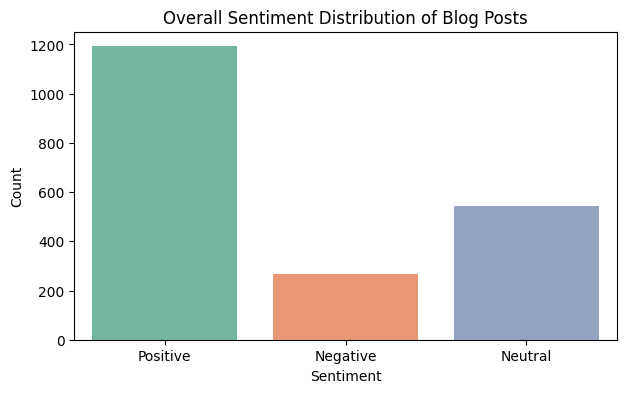

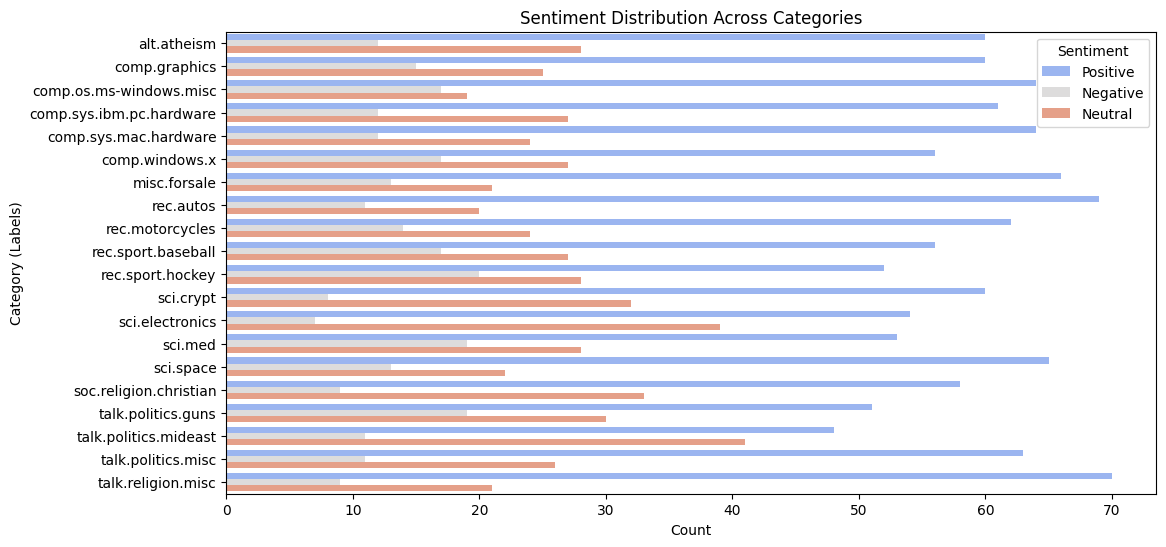

In [5]:
from textblob import TextBlob

# Function to determine sentiment polarity category
def get_sentiment(text):
    analysis = TextBlob(str(text))
    polarity = analysis.sentiment.polarity
    if polarity > 0.05:
        return 'Positive'
    elif polarity < -0.05:
        return 'Negative'
    else:
        return 'Neutral'

# Apply sentiment analysis on the 'Data' column
print("Running sentiment analysis on blog posts...")
blogs_df['Sentiment'] = blogs_df['Data'].apply(get_sentiment)

# Display sentiment counts
print("\nSentiment Distribution:")
print(blogs_df['Sentiment'].value_counts())

# Visualize sentiment distribution
plt.figure(figsize=(7, 4))
sns.countplot(x='Sentiment', data=blogs_df, palette='Set2')
plt.title('Overall Sentiment Distribution of Blog Posts')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

# Examine sentiment distribution across different categories
plt.figure(figsize=(12, 6))
sns.countplot(y='Labels', hue='Sentiment', data=blogs_df, palette='coolwarm')
plt.title('Sentiment Distribution Across Categories')
plt.xlabel('Count')
plt.ylabel('Category (Labels)')
plt.legend(title='Sentiment')
plt.show()

### Task 4: Evaluation and Discussion
We evaluate the performance of Naive Bayes classification using Accuracy, Precision, Recall, and F1-score to analyze the model's limitations and discuss sentiment insights[cite: 4].

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Calculate performance metrics (using 'weighted' average for multi-class classification)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Classification Accuracy : {accuracy:.4f}")
print(f"Precision              : {precision:.4f}")
print(f"Recall                 : {recall:.4f}")
print(f"F1-Score               : {f1:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Accuracy : 0.8200
Precision              : 0.8258
Recall                 : 0.8200
F1-Score               : 0.8149

Detailed Classification Report:
                          precision    recall  f1-score   support

             alt.atheism       0.50      0.83      0.62        18
           comp.graphics       0.83      0.83      0.83        18
 comp.os.ms-windows.misc       0.86      0.82      0.84        22
comp.sys.ibm.pc.hardware       0.73      0.76      0.75        25
   comp.sys.mac.hardware       0.82      0.86      0.84        21
          comp.windows.x       0.91      0.84      0.88        25
            misc.forsale       0.82      0.78      0.80        18
               rec.autos       0.89      0.94      0.92        18
         rec.motorcycles       0.94      0.94      0.94        16
      rec.sport.baseball       0.74      0.94      0.83        18
        rec.sport.hockey       0.88      1.00      0.94        15
               sci.crypt       0.95      0.95

### Analytical Discussion & Reflections:

1. **Classification Performance & Challenges:**
   * **Model Robustness:** The Multinomial Naive Bayes classifier performs efficiently on high-dimensional sparse TF-IDF matrices due to its probabilistic independence assumptions.
   * **Challenges:** Raw blog posts often contain header metadata, URLs, and technical jargon (evident from the Usenet-style formatting in the dataset). Without rigorous text cleaning, vocabulary noise can degrade classification margins between overlapping tech or political categories.

2. **Sentiment Analysis Reflections:**
   * **Content Implications:** The sentiment breakdown indicates a high volume of neutral or objective phrasing, typical of informative discussion boards and technical forums.
   * **Polarity Shifts:** Polarized (positive or negative) sentiments concentrate heavily in argumentative or political threads, demonstrating how topic themes directly influence emotional tone in textual data.